# 05 · Geometry Features per Candidate (Milestone 2 · Person 3)

**Goal.** For every (GPS observation, candidate arc) pair, compute geometry features for the candidate-ranking model:

| Group | Features |
|---|---|
| Distance | `dist_to_segment_m` – perpendicular distance from the GPS point to the arc segment |
| Position along segment | `proj_offset_m`, `proj_fraction`, `proj_remaining_m`, `proj_is_endpoint` |
| Segment | `seg_length_m`, `arc_is_zero_length` |
| Direction | `gps_heading_deg`, `heading_valid`, `arc_bearing_deg`, `bearing_diff_deg`, `bearing_diff_undirected_deg` |
| Connectivity | `from_/to_in_degree`, `from_/to_out_degree`, `arc_is_two_way`, `arc_parallel_count`, `arc_in_largest_scc`, `arc_wcc_fraction` |

Full definitions are in [`docs/geometry_features.md`](../docs/geometry_features.md); code in
[`src/pathsnap/features/geometry.py`](../src/pathsnap/features/geometry.py).

**Dependencies.**
* Projection: Member 1's loader (`load_trip(..., project_utm=True)` → `track_utm`, `nodes_utm`, `utm_crs`).
* Topology: Person 3's `pathsnap.road_network` (degrees, components, arc validation).
* **Candidates: Person 1's `generate_candidates()`** (`pathsnap.features.candidates`, columns
  `trip_id, obs_idx, arc_id, distance_m`) with the project defaults from `configs/candidates.yaml`: radius 50 m, at most
  30 candidates per point.
* Labels come from Person 2. They are not used here; Section 6 uses a crude *on-route* proxy only for a first look.

## 1. Setup

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shapely
from IPython.display import display

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from pathsnap.data.loader import discover_trips, load_trip       # Member 1
from pathsnap.utils.config import get_raw_data_dir
from pathsnap import road_network as rn                          # Person 3 (milestone 1)
from pathsnap.features import geometry as geo                    # Person 3 (this milestone)

SEED = 42
OUT_DIR = REPO_ROOT / "outputs" / "features" / "geometry"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)

trips_index = discover_trips(get_raw_data_dir())
split = rn.load_split()
PARTS = ["train", "student_test"]
plan = [(t, p) for p in PARTS for t in split[p] if t in trips_index]
print("Trips:", len(plan), {p: sum(q == p for _, q in plan) for p in PARTS})

[INFO] 2026-11-18 12:34:08,585 - pathsnap.data.loader: Discovered 90 trips in C:\Users\Mateen\OneDrive\Desktop\ML-Hackathon-PT-082\data\raw


Trips: 90 {'train': 80, 'student_test': 10}


## 2. Are distances and bearings computed in projected coordinates?
Every feature is computed from `track_utm` / `nodes_utm` (metres, trip-specific UTM zone). For every trip we check:

* the CRS is a WGS84 / UTM zone (`EPSG:326xx` north or `EPSG:327xx` south);
* **distances**: UTM segment length ÷ haversine length should be ≈ 1. Deviations of a few tenths of a percent are expected:
  the UTM scale factor (0.9996 on the central meridian, larger towards the zone edges) plus the spherical-Earth
  approximation of the haversine reference;
* **bearings**: UTM grid bearing − geodesic azimuth is the *grid convergence*. It can reach a few degrees away from the
  central meridian, but it is almost **constant inside one trip**, and because the GPS heading and the arc bearing are both
  measured on the same grid, their difference (the feature) is unaffected. We report its spread (p99 − p1) per trip.

In [2]:
proj_rows = []
t0 = time.time()
for tid, part in plan:
    trip = load_trip(tid, trips_index=trips_index, partition=part, project_utm=True)
    proj_rows.append({"trip_id": tid, "partition": part, **geo.check_projected_geometry(trip, seed=SEED)})
    del trip
proj = pd.DataFrame(proj_rows)
proj.to_csv(OUT_DIR / "projection_check.csv", index=False)
print(f"checked {len(proj)} trips in {time.time() - t0:.1f} s")
print("All trips in a UTM CRS:", bool(proj.is_utm.all()), "| distinct CRS:", proj.utm_crs.nunique())
display(proj[["length_ratio_median", "length_ratio_max_dev_pct", "bearing_offset_median_deg", "bearing_offset_spread_deg"]]
        .describe().T.round(4))
display(proj.sort_values("bearing_offset_spread_deg", ascending=False).head(5))

checked 90 trips in 6.9 s
All trips in a UTM CRS: True | distinct CRS: 25


,count,mean,std,min,25%,50%,75%,max
length_ratio_median,90.0,1.0012,0.0011,0.9978,1.0006,1.0015,1.0020,1.0029
length_ratio_max_dev_pct,90.0,0.3017,0.0566,0.2067,0.2714,0.2963,0.3230,0.5539
bearing_offset_median_deg,90.0,0.3477,1.2467,-2.4624,-0.4507,0.4080,1.4152,2.4853
bearing_offset_spread_deg,90.0,0.1412,0.1683,0.0033,0.0483,0.0717,0.1569,0.8854


,trip_id,partition,utm_crs,is_utm,arcs_compared,length_ratio_median,length_ratio_max_dev_pct,bearing_offset_median_deg,bearing_offset_spread_deg
22,00000028,train,EPSG:32641,True,4926,1.002102,0.333756,1.534224,0.885394
53,00000066,train,EPSG:32639,True,4978,1.001829,0.319507,1.420223,0.728852
25,00000032,train,EPSG:32633,True,4907,1.001796,0.320007,1.641798,0.717316
80,00000000,student_test,EPSG:32640,True,4940,1.002265,0.339723,2.177339,0.593275
10,00000013,train,EPSG:32631,True,4723,1.000708,0.251030,0.841148,0.471122


## 3. Candidates (Person 1)
Candidates are generated with Person 1's `generate_candidates()` using the project defaults
(`configs/candidates.yaml`: radius 50 m, cap 30 nearest arcs). Its `distance_m` must equal our `dist_to_segment_m`
because both are computed in the same UTM projection — this is asserted for every trip below.

In [3]:
from pathsnap.features.candidates import generate_candidates   # Person 1
RADIUS_M, MAX_CANDIDATES = 50.0, 30

## 4. Compute features for all trips (one trip in memory at a time)
For each trip: load + project (Member 1) → arc-level features once → Person 1's candidates → `compute_geometry_features`.
Timings are recorded to check speed on the largest networks. Only a reproducible **10 % sample of observations** of the
training trips is kept for plots; per-trip summaries are kept for all trips.

In [4]:
rng = np.random.default_rng(SEED)
summary_rows, samples = [], []
for tid, part in plan:
    trip = load_trip(tid, trips_index=trips_index, partition=part, project_utm=True)
    t0 = time.perf_counter(); arc_static = geo.compute_arc_static_features(trip.nodes_utm, trip.arcs); t_arc = time.perf_counter() - t0
    t0 = time.perf_counter(); cand = generate_candidates(trip, radius_m=RADIUS_M, max_candidates=MAX_CANDIDATES, use_index_cache=False); t_cand = time.perf_counter() - t0
    t0 = time.perf_counter(); feats = geo.compute_geometry_features(cand, trip.track_utm, arc_static); t_feat = time.perf_counter() - t0

    # invariants
    assert len(feats) == len(cand) and (feats[["obs_idx", "arc_id"]].to_numpy() == cand[["obs_idx", "arc_id"]].to_numpy()).all()
    assert np.allclose(feats.dist_to_segment_m, feats.distance_m, atol=1e-6), "feature distance != Person 1 distance_m"
    assert feats.proj_fraction.between(0, 1).all() and (feats.dist_to_segment_m >= 0).all()
    bd = feats.bearing_diff_deg.dropna()
    assert bd.between(0, 180).all()
    assert not feats.duplicated(["obs_idx", "arc_id"]).any()

    n_obs = len(trip.track)
    summary_rows.append({
        "trip_id": tid, "partition": part, "n_nodes": len(trip.nodes), "n_arcs": len(trip.arcs), "n_obs": n_obs,
        "n_candidates": len(feats), "obs_without_candidate_pct": 100 * (1 - feats.obs_idx.nunique() / n_obs),
        "mean_candidates_per_obs": len(feats) / max(feats.obs_idx.nunique(), 1),
        "heading_invalid_pct": 100 * (~feats.drop_duplicates("obs_idx").heading_valid).mean(),
        "proj_is_endpoint_pct": 100 * feats.proj_is_endpoint.mean(),
        "zero_length_candidates": int(feats.arc_is_zero_length.sum()),
        "t_arc_static_s": t_arc, "t_candidates_s": t_cand, "t_features_s": t_feat,
        "features_per_s": len(feats) / max(t_feat, 1e-9),
    })
    if part == "train":
        keep = rng.random(n_obs) < 0.10
        s = feats[keep[feats.obs_idx.to_numpy()]].copy()
        s["on_route"] = s.arc_id.isin(set(trip.route.tolist()))   # crude proxy, NOT Person 2's labels
        samples.append(s)
    del trip, arc_static, cand, feats

feat_summary = pd.DataFrame(summary_rows)
sample = pd.concat(samples, ignore_index=True)
feat_summary.to_csv(OUT_DIR / "geometry_feature_summary.csv", index=False)
print("All invariants passed for", len(feat_summary), "trips.")
print(f"Candidates: {feat_summary.n_candidates.sum():,} | sampled rows kept for plots: {len(sample):,}")

All invariants passed for 90 trips.
Candidates: 1,972,067 | sampled rows kept for plots: 174,566


### 4.1 Speed on large networks

,trip_id,n_arcs,n_obs,n_candidates,t_arc_static_s,t_candidates_s,t_features_s,features_per_s
10,00000013,307392,2580,23548,5.239,1.091,0.014,1674131.581
25,00000032,259437,2464,19424,4.405,1.169,0.023,858409.309
69,00000086,237656,4143,20097,3.973,0.895,0.011,1766443.115
35,00000043,215620,2322,22761,4.018,0.838,0.014,1580262.855
45,00000055,198961,2472,14086,3.163,0.880,0.011,1272517.029


Total time  arc-level: 69.4 s | candidate generation (Person 1): 18.3 s | candidate features: 1.1 s


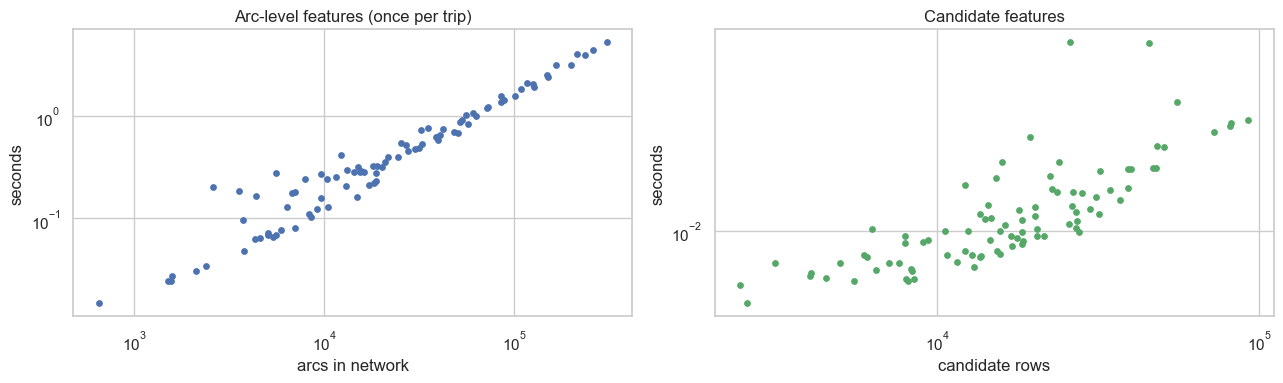

In [5]:
display(feat_summary.nlargest(5, "n_arcs")[["trip_id", "n_arcs", "n_obs", "n_candidates", "t_arc_static_s", "t_candidates_s",
                                             "t_features_s", "features_per_s"]].round(3))
print("Total time  arc-level: %.1f s | candidate generation (Person 1): %.1f s | candidate features: %.1f s"
      % tuple(feat_summary[["t_arc_static_s", "t_candidates_s", "t_features_s"]].sum()))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(feat_summary.n_arcs, feat_summary.t_arc_static_s, s=15)
ax[0].set(xscale="log", yscale="log", xlabel="arcs in network", ylabel="seconds", title="Arc-level features (once per trip)")
ax[1].scatter(feat_summary.n_candidates, feat_summary.t_features_s, s=15, color="#55A868")
ax[1].set(xscale="log", yscale="log", xlabel="candidate rows", ylabel="seconds", title="Candidate features")
plt.tight_layout(); plt.savefig(FIG_DIR / "speed.png", dpi=120); plt.show()

### 4.2 Per-trip coverage and missing values

In [6]:
cols = ["obs_without_candidate_pct", "mean_candidates_per_obs", "heading_invalid_pct", "proj_is_endpoint_pct", "zero_length_candidates"]
display(feat_summary.groupby("partition")[cols].describe().T.round(2))

partition                        student_test  train
obs_without_candidate_pct count         10.00  80.00
                          mean           0.00   1.43
                          std            0.00   9.59
                          min            0.00   0.00
                          25%            0.00   0.00
                          50%            0.00   0.00
                          75%            0.00   0.00
                          max            0.00  85.53
mean_candidates_per_obs   count         10.00  80.00
                          mean          11.13  11.20
                          std            5.03   4.80
                          min            3.70   3.00
                          25%            6.41   7.94
                          50%           12.04  10.50
                          75%           13.97  14.31
                          max           18.23  22.95
heading_invalid_pct       count         10.00  80.00
                          mean           0.03   0.07
                          std            0.04   0.08
                          min            0.00   0.00
                          25%            0.00   0.00
                          50%            0.00   0.04
                          75%            0.04   0.13
                          max            0.11   0.29
proj_is_endpoint_pct      count         10.00  80.00
                          mean          64.38  66.64
                          std           12.52  10.62
                          min           40.56  30.49
                          25%           56.30  62.40
                          50%           68.73  67.50
                          75%           73.25  74.77
                          max           77.40  83.27
zero_length_candidates    count         10.00  80.00
                          mean           0.00   0.00
                          std            0.00   0.00
                          min            0.00   0.00
                          25%            0.00   0.00
                          50%            0.00   0.00
                          75%            0.00   0.00
                          max            0.00   0.00

## 5. Feature distributions (training trips, 10 % sample)

In [7]:
num = ["dist_to_segment_m", "proj_fraction", "seg_length_m", "bearing_diff_deg", "bearing_diff_undirected_deg",
       "to_out_degree", "from_in_degree", "arc_wcc_fraction"]
display(sample[num].describe().T.round(3))
print("Boolean shares:", sample[["heading_valid", "proj_is_endpoint", "arc_is_two_way", "arc_in_largest_scc", "arc_is_zero_length"]]
      .mean().round(4).to_dict())

,count,mean,std,min,25%,50%,75%,max
dist_to_segment_m,174566.0,24.117,14.873,0.00,10.483,23.976,37.183,50.000
proj_fraction,174566.0,0.498,0.444,0.00,0.000,0.493,1.000,1.000
seg_length_m,174566.0,84.579,193.831,0.14,15.236,34.542,79.886,4671.058
bearing_diff_deg,174383.0,88.257,61.891,0.00,25.471,87.248,151.102,180.000
bearing_diff_undirected_deg,174383.0,34.859,28.159,0.00,9.353,27.083,59.429,89.999
to_out_degree,174566.0,2.076,0.760,0.00,2.000,2.000,2.000,7.000
from_in_degree,174566.0,2.074,0.760,0.00,2.000,2.000,2.000,7.000
arc_wcc_fraction,174566.0,0.967,0.066,0.00,0.963,0.982,0.989,1.000


Boolean shares: {'heading_valid': 0.999, 'proj_is_endpoint': 0.6717, 'arc_is_two_way': 0.7548, 'arc_in_largest_scc': 0.9867, 'arc_is_zero_length': 0.0}


## 6. First look at separability (crude proxy)
`on_route` = the candidate arc appears **anywhere** in the trip's `.route` (training trips only). This is *not* the per-point
label: Person 2 builds the real reference arc per observation. The proxy is enough to see whether a feature carries signal.

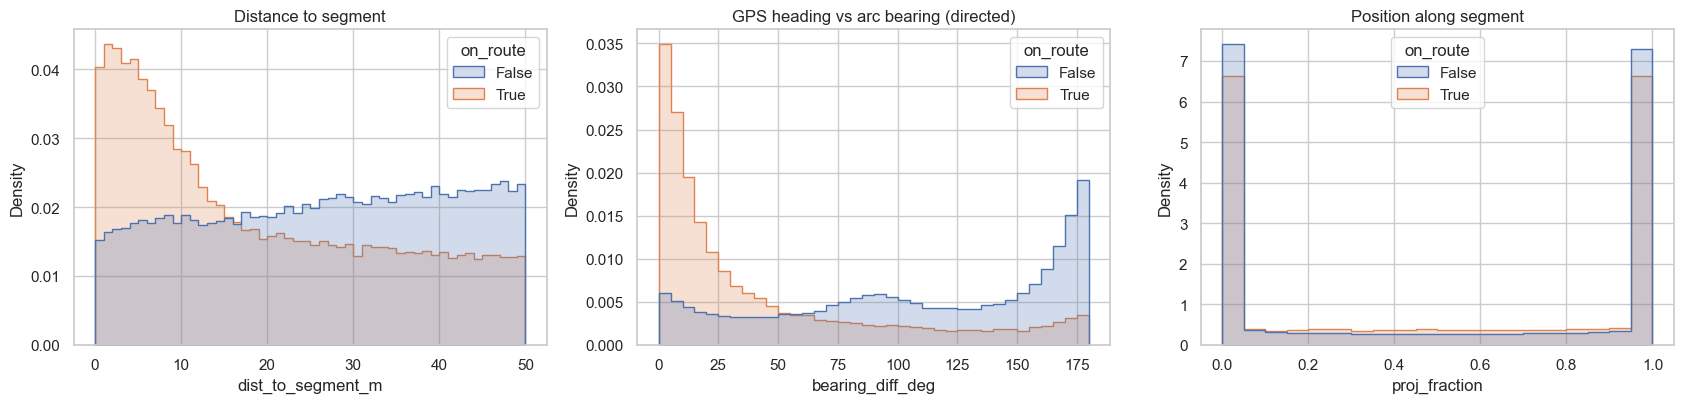

,median_on_route,median_off_route
dist_to_segment_m,15.08,27.28
bearing_diff_deg,21.82,114.07
bearing_diff_undirected_deg,17.59,33.46


Share of on-route candidates with bearing_diff > 135° (driving against the arc): 10.27 %


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
sns.histplot(data=sample, x="dist_to_segment_m", hue="on_route", bins=50, stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].set_title("Distance to segment")
sns.histplot(data=sample[sample.heading_valid], x="bearing_diff_deg", hue="on_route", bins=36, stat="density",
             common_norm=False, element="step", ax=axes[1])
axes[1].set_title("GPS heading vs arc bearing (directed)")
sns.histplot(data=sample, x="proj_fraction", hue="on_route", bins=20, stat="density", common_norm=False, element="step", ax=axes[2])
axes[2].set_title("Position along segment")
plt.tight_layout(); plt.savefig(FIG_DIR / "feature_distributions.png", dpi=120); plt.show()

hv = sample[sample.heading_valid]
sep = pd.DataFrame({
    "median_on_route": sample.groupby("on_route")[["dist_to_segment_m"]].median().loc[True].tolist()
                       + [hv[hv.on_route].bearing_diff_deg.median(), hv[hv.on_route].bearing_diff_undirected_deg.median()],
    "median_off_route": sample.groupby("on_route")[["dist_to_segment_m"]].median().loc[False].tolist()
                        + [hv[~hv.on_route].bearing_diff_deg.median(), hv[~hv.on_route].bearing_diff_undirected_deg.median()],
}, index=["dist_to_segment_m", "bearing_diff_deg", "bearing_diff_undirected_deg"]).round(2)
display(sep)
print("Share of on-route candidates with bearing_diff > 135° (driving against the arc):",
      round(100 * (hv[hv.on_route].bearing_diff_deg > 135).mean(), 2), "%")

## 7. Findings

In [9]:
fs, p = feat_summary, proj
big = fs.loc[fs.n_arcs.idxmax()]
facts = [
    f"{len(fs)} trips processed ({(fs.partition == 'train').sum()} train, {(fs.partition == 'student_test').sum()} student_test); "
    f"{fs.n_candidates.sum():,} candidate rows from Person 1 (r = 50 m, cap 30); all invariants passed (row order kept, no duplicate (obs, arc), "
    f"distance = Person 1's distance_m, fraction in [0,1], bearing diff in [0,180]).",
    f"Projection: {int(p.is_utm.sum())}/{len(p)} trips in a UTM CRS; UTM/haversine length ratio median "
    f"{p.length_ratio_median.median():.5f}, worst deviation {p.length_ratio_max_dev_pct.max():.3f} %.",
    f"Grid convergence (UTM grid bearing − geodesic azimuth): per-trip median ranges {p.bearing_offset_median_deg.min():.2f}° to "
    f"{p.bearing_offset_median_deg.max():.2f}°, but its spread inside a trip is at most {p.bearing_offset_spread_deg.max():.3f}°.",
    f"Largest network ({big.trip_id}, {int(big.n_arcs):,} arcs): arc features {big.t_arc_static_s:.2f} s, "
    f"candidate features {big.t_features_s:.3f} s for {int(big.n_candidates):,} rows.",
    f"GPS heading invalid (moved < 2 m around the point) for a median {fs.heading_invalid_pct.median():.2f} % of observations "
    f"(max {fs.heading_invalid_pct.max():.1f} %); bearing features are NaN there and must be imputed or flagged by the model.",
    f"Projection falls on a segment end for {sample.proj_is_endpoint.mean():.1%} of sampled candidates.",
]
for i, f in enumerate(facts, 1):
    print(f"{i}. {f}")

1. 90 trips processed (80 train, 10 student_test); 1,972,067 candidate rows from Person 1 (r = 50 m, cap 30); all invariants passed (row order kept, no duplicate (obs, arc), distance = Person 1's distance_m, fraction in [0,1], bearing diff in [0,180]).
2. Projection: 90/90 trips in a UTM CRS; UTM/haversine length ratio median 1.00146, worst deviation 0.554 %.
3. Grid convergence (UTM grid bearing − geodesic azimuth): per-trip median ranges -2.46° to 2.49°, but its spread inside a trip is at most 0.885°.
4. Largest network (00000013, 307,392 arcs): arc features 5.24 s, candidate features 0.014 s for 23,548 rows.
5. GPS heading invalid (moved < 2 m around the point) for a median 0.04 % of observations (max 0.3 %); bearing features are NaN there and must be imputed or flagged by the model.
6. Projection falls on a segment end for 67.2% of sampled candidates.


### Notes for the team
* **Person 1:** `generate_candidates()` output plugs in directly; its `distance_m` equals `dist_to_segment_m` on every
  trip (asserted above), confirming both use the same UTM geometry.
* **Person 2:** `bearing_diff_deg` near 180° on the reference arc would indicate a reversed reference — a useful check
  for the alignment.
* **Trip `00000054`:** 85.5 % of its GPS points have no arc within 50 m (next worst: `00000002` 7.0 %, `00000096` 4.4 %).
  The Task 4 route check found the same trip ~130 m from its route, so its GPS appears offset from the whole road map, not
  just the route. Person 1 / Person 2 should decide whether to exclude it from training.
* **Person 4:** `compute_gps_heading()` is exported; reuse it for the per-observation heading so both feature groups share
  one definition. Missing headings (`heading_valid == False`) need a policy (e.g. impute 90° + flag). No feature here is
  fitted or scaled, so there is no train/test leakage; any scaling belongs to the assembly step on training trips only.